# Исследование данных Titanic


In [1]:
from google.colab import files
import os
if not os.path.exists("titanic.csv"):
    up = files.upload()
    name = list(up.keys())[0]
    os.rename(name, "titanic.csv")

## Часть 4. Подготовка данных

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("titanic.csv")
print(df.head())

features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

print(X.isnull().sum())
print(X.dtypes)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Pc

## Часть 5. Корреляционный анализ

Survived    1.000000
Sex         0.543351
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.064910
Pclass     -0.338481
Name: Survived, dtype: float64


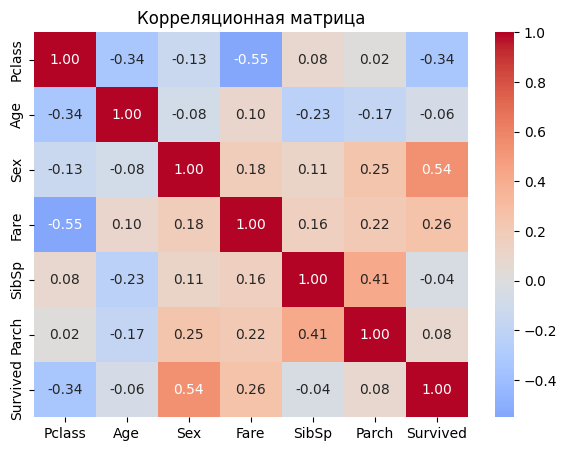

In [3]:
data_corr = X.copy()
data_corr["Survived"] = y
corr = data_corr.corr()
print(corr["Survived"].sort_values(ascending=False))

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица")
plt.show()

## Часть 6. Логистическая регрессия

In [4]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [5]:
y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы:", y_test.iloc[:10].to_list())

Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы: [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print("Матрица ошибок:\n", confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8044692737430168
Precision: 0.765625
Recall: 0.7101449275362319
F1: 0.7368421052631579
Матрица ошибок:
 [[95 15]
 [20 49]]
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



## Дерево решений

Accuracy дерева: 0.7821229050279329
Precision: 0.875
Recall: 0.5072463768115942
F1: 0.6422018348623854
Матрица ошибок:
 [[105   5]
 [ 34  35]]
           Логистическая регрессия  Дерево решений
Accuracy                     0.804           0.782
Precision                    0.766           0.875
Recall                       0.710           0.507
F1                           0.737           0.642


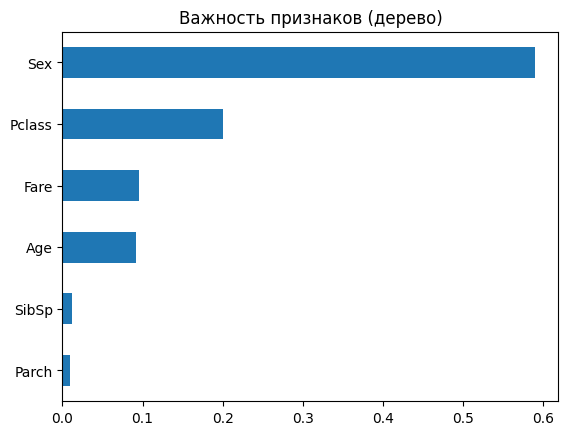

In [7]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print("Accuracy дерева:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1:", f1_score(y_test, y_pred_tree))
print("Матрица ошибок:\n", confusion_matrix(y_test, y_pred_tree))

res = pd.DataFrame({
    "Логистическая регрессия": [accuracy_score(y_test, y_pred_lr), precision_score(y_test, y_pred_lr),
                                recall_score(y_test, y_pred_lr), f1_score(y_test, y_pred_lr)],
    "Дерево решений": [accuracy_score(y_test, y_pred_tree), precision_score(y_test, y_pred_tree),
                       recall_score(y_test, y_pred_tree), f1_score(y_test, y_pred_tree)],
}, index=["Accuracy", "Precision", "Recall", "F1"]).round(3)
print(res)

imp = pd.Series(model_tree.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", title="Важность признаков (дерево)")
plt.show()